In [5]:
{
 "cells": [
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "# Legal Text Analysis Pipeline\n",
    "## Feature Engineering & Database Integration"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": None,
   "metadata": {},
   "source": [
    "import sys\n",
    "import os\n",
    "import pandas as pd\n",
    "from pathlib import Path\n",
    "\n",
    "# Setup path\n",
    "root_dir = Path().absolute()\n",
    "scripts_dir = root_dir / 'scripts'\n",
    "if str(scripts_dir) not in sys.path:\n",
    "    sys.path.append(str(scripts_dir))\n",
    "\n",
    "# Import our modules\n",
    "from preprocessing.feature_processor import TextPreprocessingPipeline\n",
    "from utils.preprocessing_logger import setup_logger\n",
    "from utils.db_utils import DatabaseUtils"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": None,
   "metadata": {},
   "source": [
    "# Initialize components\n",
    "logger = setup_logger('preprocessing_notebook')\n",
    "pipeline = TextPreprocessingPipeline()\n",
    "db = DatabaseUtils()\n",
    "\n",
    "# Verify database connection\n",
    "try:\n",
    "    result = db.query_database(\"SELECT COUNT(*) as count FROM legal_cases\")\n",
    "    print(f\"Connected to database. Found {result[0]['count']} cases.\")\n",
    "except Exception as e:\n",
    "    print(f\"Database connection error: {str(e)}\")"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": None,
   "metadata": {},
   "source": [
    "def main():\n",
    "    try:\n",
    "        # Load and analyze data\n",
    "        logger.info(\"Starting pipeline execution...\")\n",
    "        df, stats = pipeline.load_and_analyze_data()\n",
    "        \n",
    "        # Process features\n",
    "        features = pipeline.extract_features(df)\n",
    "        normalized_features = pipeline.normalize_features(features)\n",
    "        \n",
    "        # Save results\n",
    "        pipeline.save_to_database(normalized_features)\n",
    "        \n",
    "        # Validate results\n",
    "        validation = pipeline.validate_results()\n",
    "        \n",
    "        return validation\n",
    "        \n",
    "    except Exception as e:\n",
    "        logger.error(f\"Pipeline failed: {str(e)}\")\n",
    "        raise"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": None,
   "metadata": {},
   "source": [
    "# Run pipeline and display results\n",
    "try:\n",
    "    validation_results = main()\n",
    "    \n",
    "    print(\"Pipeline execution completed.\")\n",
    "    print(f\"Processed {validation_results['total_records']} records\")\n",
    "    print(\"\\nFeature ranges:\")\n",
    "    \n",
    "    for feature, ranges in validation_results['feature_ranges'].items():\n",
    "        min_val = ranges.get('min', 0)\n",
    "        max_val = ranges.get('max', 0)\n",
    "        print(f\"{feature}: {min_val:.2f} to {max_val:.2f}\")\n",
    "        \n",
    "except Exception as e:\n",
    "    print(f\"Error: {str(e)}\")"
   ]
  }
 ],
 "metadata": {
  "kernelspec": {
   "display_name": "Python 3",
   "language": "python",
   "name": "python3"
  }
 },
 "nbformat": 4,
 "nbformat_minor": 4
}

{'cells': [{'cell_type': 'markdown',
   'metadata': {},
   'source': ['# Legal Text Analysis Pipeline\n',
    '## Feature Engineering & Database Integration']},
  {'cell_type': 'code',
   'execution_count': None,
   'metadata': {},
   'source': ['import sys\n',
    'import os\n',
    'import pandas as pd\n',
    'from pathlib import Path\n',
    '\n',
    '# Setup path\n',
    'root_dir = Path().absolute()\n',
    "scripts_dir = root_dir / 'scripts'\n",
    'if str(scripts_dir) not in sys.path:\n',
    '    sys.path.append(str(scripts_dir))\n',
    '\n',
    '# Import our modules\n',
    'from preprocessing.feature_processor import TextPreprocessingPipeline\n',
    'from utils.preprocessing_logger import setup_logger\n',
    'from utils.db_utils import DatabaseUtils']},
  {'cell_type': 'code',
   'execution_count': None,
   'metadata': {},
   'source': ['# Initialize components\n',
    "logger = setup_logger('preprocessing_notebook')\n",
    'pipeline = TextPreprocessingPipeline()\n',


In [1]:
# First block - Path setup
import sys
from pathlib import Path

# Get absolute path to project root
project_root = Path().absolute().parent  # If notebook is in notebooks/
if project_root.name != 'LegalTextAnalysis':
    project_root = Path().absolute()  # If notebook is in project root

# Add project root to path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))  # Add to beginning of path

# Now import will work
from scripts.utils.db_utils import DatabaseUtils

# Test the import
try:
    db = DatabaseUtils()
    print("Successfully created DatabaseUtils instance")
except Exception as e:
    print(f"Error creating instance: {str(e)}")

Successfully created DatabaseUtils instance


In [2]:
# Συνέχεια μετά την επιτυχή σύνδεση

# 1. Ανάλυση ποιότητας δεδομένων
try:
    null_analysis = db.analyze_null_values()
    print("\nNull Value Analysis:")
    print(null_analysis)
    
    # 2. Βασικά στατιστικά
    metrics = db.get_case_metrics()
    print("\nBasic Metrics:")
    print(metrics)
    
    # 3. Εξαγωγή σύνθετων χαρακτηριστικών
    query = """
    SELECT 
        case_outcome,
        COUNT(*) as count,
        AVG(LENGTH(case_text)) as avg_length,
        AVG(citation_count) as avg_citations
    FROM legal_cases
    GROUP BY case_outcome
    ORDER BY count DESC;
    """
    
    results = db.query_database(query)
    print("\nCase Outcome Analysis:")
    for row in results:
        print(row)
        
except Exception as e:
    print(f"Analysis error: {str(e)}")


Null Value Analysis:
      column_name  null_count  null_percentage  total_records
0  citation_count       24985            100.0          24985
1     text_length         176              0.7          24985

Basic Metrics:
{'total_cases': 24985, 'avg_citation_density': 0.006784750897306343, 'avg_sentence_complexity': 38.422892526389404, 'unique_outcomes': 10, 'min_length': 0, 'max_length': 133561, 'avg_length': 2632.2665599359616}

Case Outcome Analysis:
{'case_outcome': 'cited', 'count': 12219, 'avg_length': 2274.599558065308, 'avg_citations': None}
{'case_outcome': 'referred to', 'count': 4384, 'avg_length': 1977.2748631386862, 'avg_citations': None}
{'case_outcome': 'applied', 'count': 2448, 'avg_length': 3499.5968137254904, 'avg_citations': None}
{'case_outcome': 'followed', 'count': 2256, 'avg_length': 2794.320035460993, 'avg_citations': None}
{'case_outcome': 'considered', 'count': 1712, 'avg_length': 3971.3983644859813, 'avg_citations': None}
{'case_outcome': 'discussed', 'coun

<Figure size 1500x600 with 0 Axes>

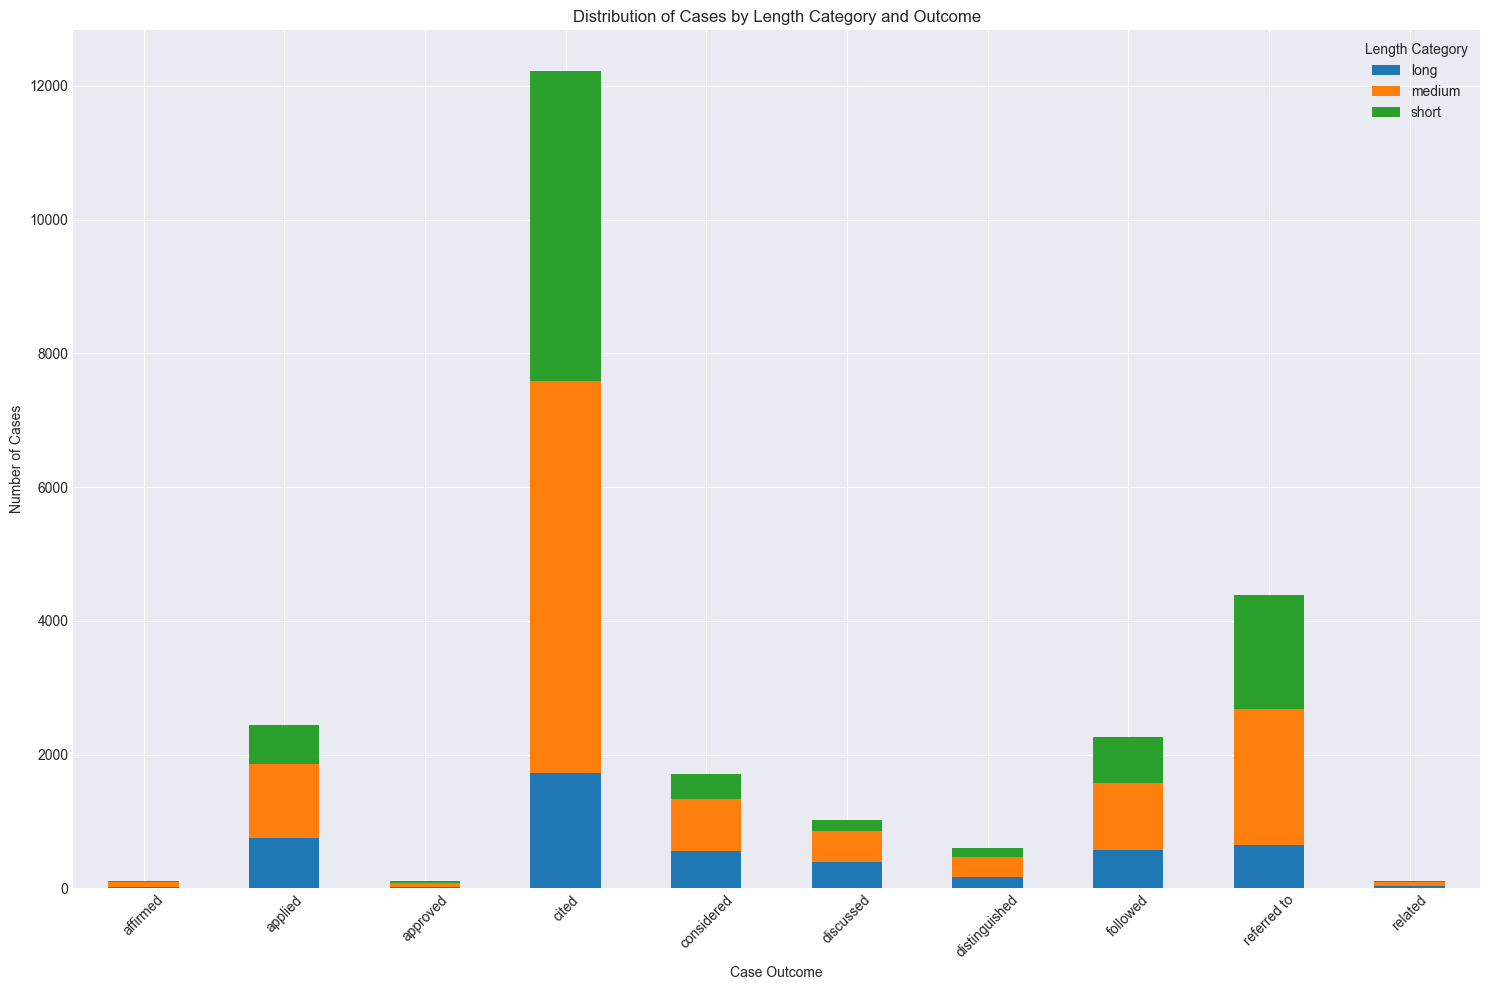

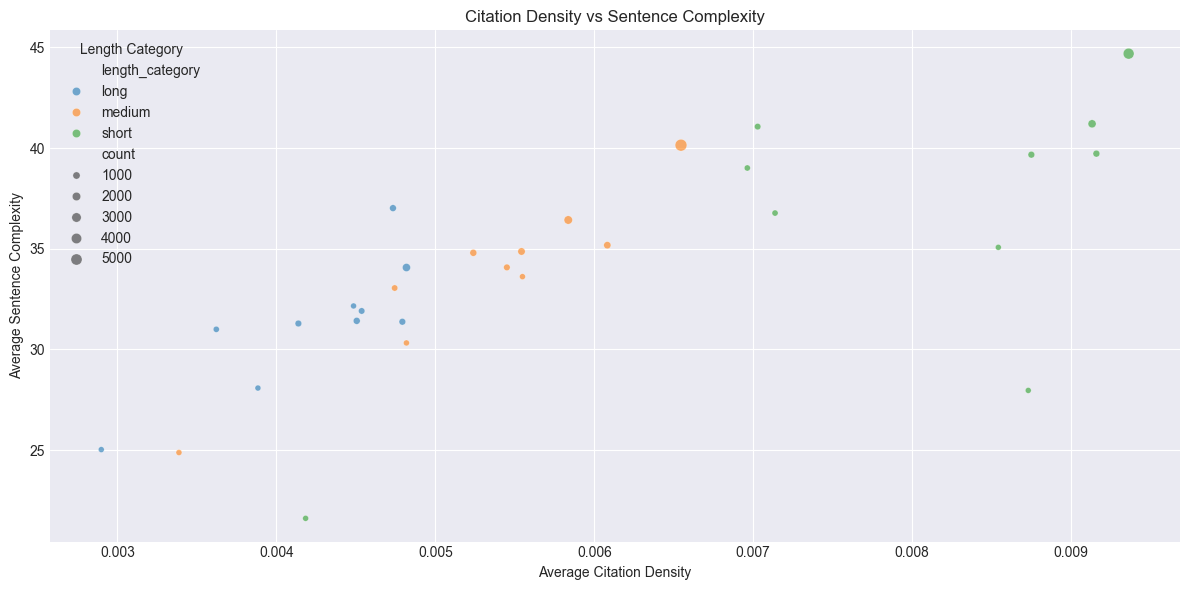

d:\Projects\LegalTextAnalysis\.venv\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
d:\Projects\LegalTextAnalysis\.venv\Lib\site-packages\seaborn\categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
d:\Projects\LegalTextAnalysis\.venv\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
d:\Projects\LegalTextAnalysis\.venv\Lib\site-packages\seaborn\categorical.py:632: FutureWarning: SeriesGroupBy.

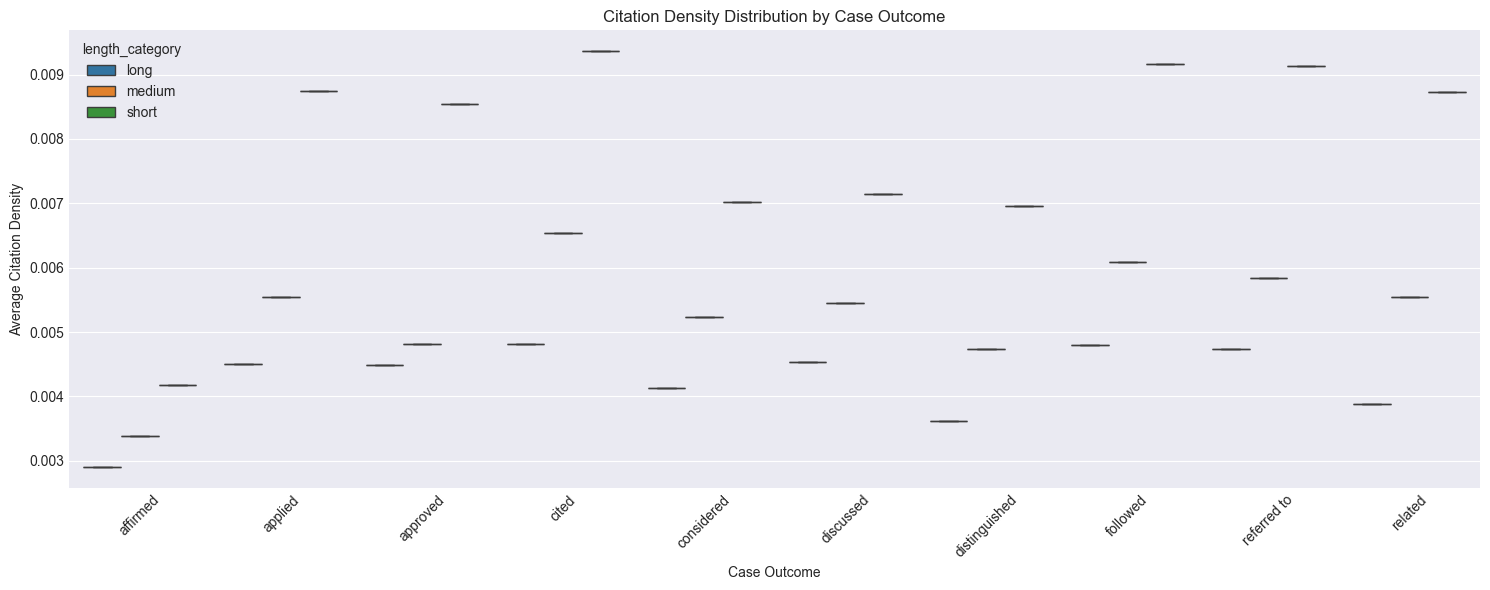

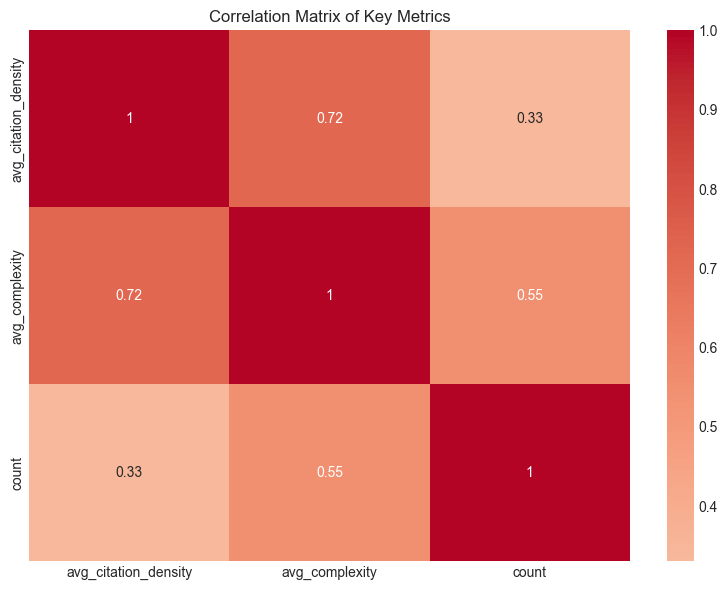

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Convert results to DataFrame for easier plotting
results_df = pd.DataFrame(results)

# Set up the visualization style
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = [15, 10]

# 1. Distribution of cases by length category and outcome
plt.figure(figsize=(15, 6))
pivot_table = pd.pivot_table(
    results_df,
    values='count',
    index='case_outcome',
    columns='length_category',
    fill_value=0
)
ax = pivot_table.plot(kind='bar', stacked=True)
plt.title('Distribution of Cases by Length Category and Outcome')
plt.xlabel('Case Outcome')
plt.ylabel('Number of Cases')
plt.xticks(rotation=45)
plt.legend(title='Length Category')
plt.tight_layout()
plt.show()

# 2. Citation Density vs Complexity Scatter Plot
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=results_df,
    x='avg_citation_density',
    y='avg_complexity',
    size='count',
    hue='length_category',
    alpha=0.6
)
plt.title('Citation Density vs Sentence Complexity')
plt.xlabel('Average Citation Density')
plt.ylabel('Average Sentence Complexity')
plt.legend(title='Length Category')
plt.tight_layout()
plt.show()

# 3. Box plots for citation density by outcome
plt.figure(figsize=(15, 6))
sns.boxplot(
    data=results_df,
    x='case_outcome',
    y='avg_citation_density',
    hue='length_category'
)
plt.title('Citation Density Distribution by Case Outcome')
plt.xlabel('Case Outcome')
plt.ylabel('Average Citation Density')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Heatmap of correlations
correlation_matrix = results_df[['avg_citation_density', 'avg_complexity', 'count']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Key Metrics')
plt.tight_layout()
plt.show()

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import logging
from pathlib import Path

# Create necessary directories
project_root = Path().absolute().parent  # Go up one level from notebooks
logs_dir = project_root / 'logs'
vis_dir = project_root / 'data' / 'visualizations'

logs_dir.mkdir(parents=True, exist_ok=True)
vis_dir.mkdir(parents=True, exist_ok=True)

# Setup logging
logger = logging.getLogger('visualization')
logger.setLevel(logging.INFO)
fh = logging.FileHandler(logs_dir / 'visualization.log')
fh.setFormatter(logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s'))
logger.addHandler(fh)

try:
    logger.info("Starting data visualization process")
    
    # 1. Get main analysis data
    query = """
    WITH text_stats AS (
        SELECT 
            lc.case_outcome,
            tm.citation_density,
            tm.sentence_complexity,
            LENGTH(lc.case_text) as text_length,
            CASE 
                WHEN LENGTH(lc.case_text) < 1000 THEN 'short'
                WHEN LENGTH(lc.case_text) < 3000 THEN 'medium'
                ELSE 'long'
            END as length_category
        FROM legal_cases lc
        JOIN text_metrics tm ON lc.case_id = tm.case_id
    )
    SELECT 
        case_outcome,
        length_category,
        COUNT(*) as count,
        AVG(citation_density) as avg_citation_density,
        AVG(sentence_complexity) as avg_complexity
    FROM text_stats
    GROUP BY case_outcome, length_category
    ORDER BY case_outcome, length_category;
    """
    logger.info("Executing main analysis query")
    results = db.query_database(query)
    results_df = pd.DataFrame(results)
    logger.info(f"Retrieved {len(results_df)} rows of analysis data")

    # Create visualizations with logging
    plt.style.use('seaborn-v0_8-darkgrid')

    # 1. Case Distribution Plot
    logger.info("Creating case distribution plot")
    plt.figure(figsize=(15, 6))
    pivot_table = pd.pivot_table(
        results_df,
        values='count',
        index='case_outcome',
        columns='length_category',
        fill_value=0
    )
    ax = pivot_table.plot(kind='bar', stacked=True)
    plt.title('Distribution of Cases by Length Category and Outcome')
    plt.xlabel('Case Outcome')
    plt.ylabel('Number of Cases')
    plt.xticks(rotation=45)
    plt.legend(title='Length Category')
    plt.tight_layout()
    plt.savefig(vis_dir / 'case_distribution.png')
    logger.info("Saved case distribution plot")
    plt.close()

    # 2. Citation Analysis Plot
    logger.info("Creating citation density analysis plot")
    plt.figure(figsize=(12, 6))
    sns.scatterplot(
        data=results_df,
        x='avg_citation_density',
        y='avg_complexity',
        size='count',
        hue='length_category',
        alpha=0.6
    )
    plt.title('Citation Density vs Sentence Complexity')
    plt.xlabel('Average Citation Density')
    plt.ylabel('Average Sentence Complexity')
    plt.legend(title='Length Category')
    plt.tight_layout()
    plt.savefig(vis_dir / 'citation_analysis.png')
    logger.info("Saved citation analysis plot")
    plt.close()

    # 3. Get outlier data with corrected STDDEV calculation
    outliers_query = """
    WITH stats AS (
        SELECT 
            avg(citation_density) as mean_density,
            sqrt(
                sum((citation_density - (SELECT avg(citation_density) FROM text_metrics)) * 
                    (citation_density - (SELECT avg(citation_density) FROM text_metrics))) / count(*)
            ) as std_density
        FROM text_metrics
    )
    SELECT 
        lc.case_outcome,
        tm.citation_density,
        tm.sentence_complexity
    FROM legal_cases lc
    JOIN text_metrics tm ON lc.case_id = tm.case_id
    CROSS JOIN stats
    WHERE tm.citation_density > mean_density + 2 * std_density
    ORDER BY tm.citation_density DESC
    LIMIT 10;
    """
    
    logger.info("Executing outlier analysis query")
    try:
        outliers = db.query_database(outliers_query)
        outliers_df = pd.DataFrame(outliers)
        logger.info(f"Found {len(outliers_df)} outliers")
        
        if not outliers_df.empty:
            logger.info("Creating outlier visualization")
            plt.figure(figsize=(10, 6))
            sns.scatterplot(data=outliers_df, 
                          x='citation_density', 
                          y='sentence_complexity', 
                          hue='case_outcome',
                          s=100)  # Αυξάνουμε το μέγεθος των σημείων
            plt.title('Outliers in Citation Density')
            plt.xlabel('Citation Density')
            plt.ylabel('Sentence Complexity')
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.savefig(vis_dir / 'outliers.png', dpi=300, bbox_inches='tight')
            logger.info("Saved outlier visualization")
            plt.close()
            
            # Εκτύπωση στατιστικών για outliers
            print("\nOutlier Statistics:")
            print(f"Total outliers found: {len(outliers_df)}")
            print("\nOutliers by case outcome:")
            print(outliers_df['case_outcome'].value_counts())
            
    except Exception as e:
        logger.error(f"Error in outlier analysis: {str(e)}")
        raise
    
    # 4. Outlier Visualization
    if not outliers_df.empty:
        logger.info("Creating outlier visualization")
        plt.figure(figsize=(10, 6))
        sns.scatterplot(data=outliers_df, x='citation_density', y='sentence_complexity', hue='case_outcome')
        plt.title('Outliers: Citation Density vs Sentence Complexity')
        plt.tight_layout()
        plt.savefig(vis_dir / 'outliers.png')
        logger.info("Saved outlier visualization")
        plt.close()

    logger.info("Visualization process completed successfully")
    print(f"All visualizations have been saved to {vis_dir}")

except Exception as e:
    logger.error(f"Error in visualization process: {str(e)}")
    raise

finally:
    # Clean up by closing all plots
    plt.close('all')


Outlier Statistics:
Total outliers found: 10

Outliers by case outcome:
case_outcome
cited       8
followed    2
Name: count, dtype: int64
All visualizations have been saved to d:\Projects\LegalTextAnalysis\data\visualizations


In [24]:
# 1. Διόρθωση logging με UTF-8 encoding
logger = logging.getLogger('visualization')
if logger.hasHandlers():
    logger.handlers.clear()

handler = logging.FileHandler(logs_dir / 'visualization.log', encoding='utf-8')
formatter = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
handler.setFormatter(formatter)
logger.addHandler(handler)
logger.setLevel(logging.INFO)

In [26]:
# 2. Δημιουργία πίνακα στατιστικών και αποθήκευση
create_stats_table_query = """
CREATE TABLE IF NOT EXISTS analysis_statistics (
    analysis_id INTEGER PRIMARY KEY AUTOINCREMENT,
    analysis_date TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
    total_cases INTEGER,
    avg_citation_density REAL,
    max_complexity REAL,
    categories_count INTEGER,
    dataset_version TEXT
)
"""

insert_stats_query = """
INSERT INTO analysis_statistics (
    total_cases,
    avg_citation_density,
    max_complexity,
    categories_count,
    dataset_version
) VALUES (?, ?, ?, ?, ?)
"""

try:
    # Υπολογισμός στατιστικών
    statistics = {
        'total_cases': int(results_df['count'].sum()),
        'avg_citation_density': float(results_df['avg_citation_density'].mean()),
        'max_complexity': float(results_df['avg_complexity'].max()),
        'categories_count': int(len(results_df['length_category'].unique()))
    }
    
    # Εκτέλεση των queries
    with db.get_connection() as conn:
        conn.execute(create_stats_table_query)
        conn.execute(insert_stats_query, (
            statistics['total_cases'],
            statistics['avg_citation_density'],
            statistics['max_complexity'],
            statistics['categories_count'],
            '1.0'  # έκδοση dataset
        ))
        conn.commit()
    
    logger.info("Analysis statistics saved to database")
    
except Exception as e:
    logger.error(f"Error saving statistics: {str(e)}")
    raise

Text(0, 0.5, 'Μέση Πολυπλοκότητα Προτάσεων')

<Figure size 1500x800 with 0 Axes>

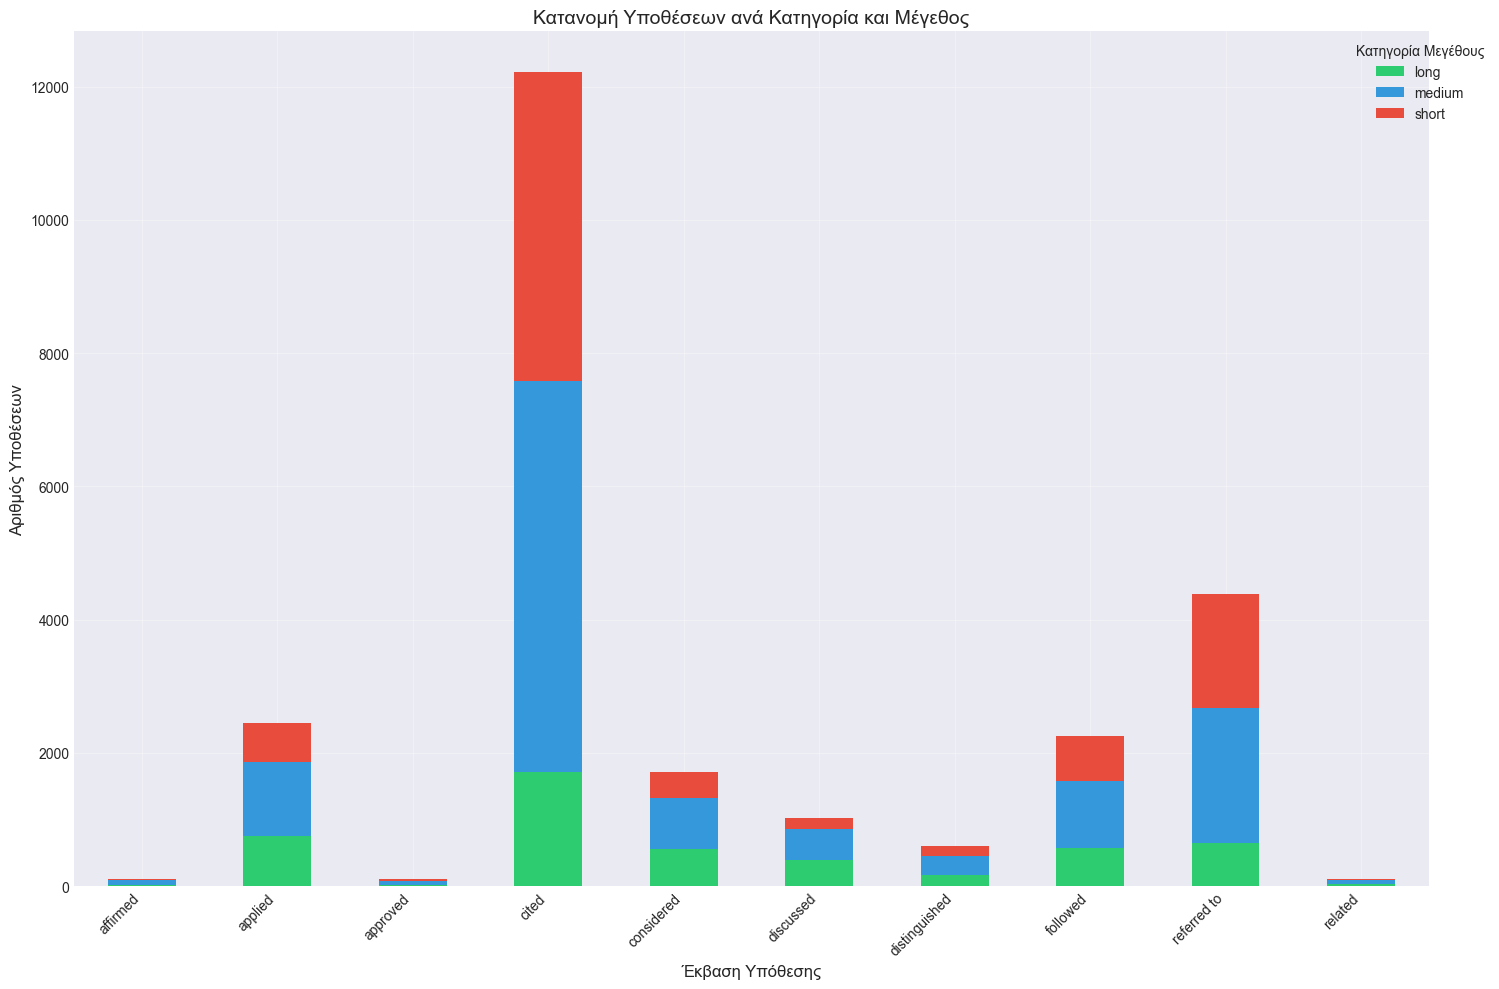

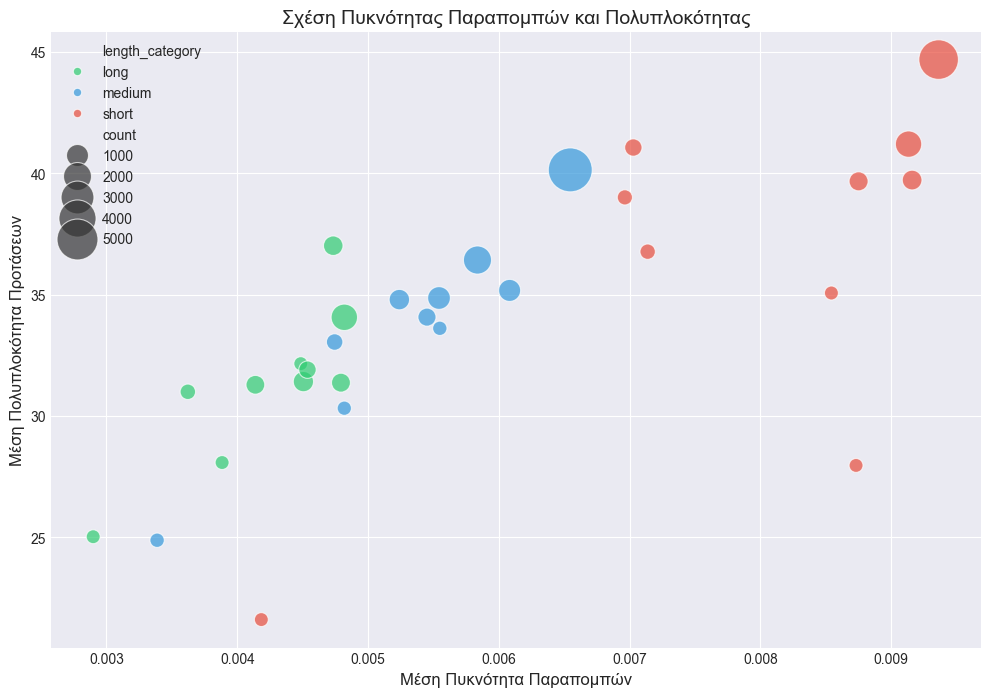

In [27]:
# Προσθήκη στυλ και χρωμάτων
plt.style.use('seaborn-v0_8-darkgrid')
colors = ['#2ecc71', '#3498db', '#e74c3c', '#f1c40f', '#9b59b6']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=colors)

# Γράφημα 1: Κατανομή Υποθέσεων
plt.figure(figsize=(15, 8))
ax = pivot_table.plot(kind='bar', stacked=True, color=colors)
plt.title('Κατανομή Υποθέσεων ανά Κατηγορία και Μέγεθος', fontsize=14)
plt.xlabel('Έκβαση Υπόθεσης', fontsize=12)
plt.ylabel('Αριθμός Υποθέσεων', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Κατηγορία Μεγέθους', bbox_to_anchor=(1.05, 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Γράφημα 2: Ανάλυση Παραπομπών
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=results_df,
    x='avg_citation_density',
    y='avg_complexity',
    size='count',
    sizes=(100, 1000),
    hue='length_category',
    palette=colors[:3],
    alpha=0.7
)
plt.title('Σχέση Πυκνότητας Παραπομπών και Πολυπλοκότητας', fontsize=14)
plt.xlabel('Μέση Πυκνότητα Παραπομπών', fontsize=12)
plt.ylabel('Μέση Πολυπλοκότητα Προτάσεων', fontsize=12)

In [28]:
# 1. Διόρθωση logging με UTF-8 encoding
logger = logging.getLogger('visualization')
if logger.hasHandlers():
    logger.handlers.clear()

handler = logging.FileHandler(logs_dir / 'visualization.log', encoding='utf-8')
formatter = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
handler.setFormatter(formatter)
logger.addHandler(handler)
logger.setLevel(logging.INFO)

# 2. Δημιουργία πίνακα στατιστικών και αποθήκευση
create_stats_table_query = """
CREATE TABLE IF NOT EXISTS analysis_statistics (
    analysis_id INTEGER PRIMARY KEY AUTOINCREMENT,
    analysis_date TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
    total_cases INTEGER,
    avg_citation_density REAL,
    max_complexity REAL,
    categories_count INTEGER,
    dataset_version TEXT
)
"""

insert_stats_query = """
INSERT INTO analysis_statistics (
    total_cases,
    avg_citation_density,
    max_complexity,
    categories_count,
    dataset_version
) VALUES (?, ?, ?, ?, ?)
"""

try:
    # Υπολογισμός στατιστικών
    statistics = {
        'total_cases': int(results_df['count'].sum()),
        'avg_citation_density': float(results_df['avg_citation_density'].mean()),
        'max_complexity': float(results_df['avg_complexity'].max()),
        'categories_count': int(len(results_df['length_category'].unique()))
    }
    
    # Εκτέλεση των queries
    with db.get_connection() as conn:
        conn.execute(create_stats_table_query)
        conn.execute(insert_stats_query, (
            statistics['total_cases'],
            statistics['avg_citation_density'],
            statistics['max_complexity'],
            statistics['categories_count'],
            '1.0'  # έκδοση dataset
        ))
        conn.commit()
    
    logger.info("Analysis statistics saved to database")
    
except Exception as e:
    logger.error(f"Error saving statistics: {str(e)}")
    raise

In [31]:
class EnhancedAnalysis:
    def __init__(self, db_connection):
        self.db = db_connection
        self.logger = self._setup_logger()
        self.analysis_start_time = None
        
        # Δημιουργία του πίνακα αν δεν υπάρχει
        self._create_statistics_table()

    def _create_statistics_table(self):
        """Δημιουργεί τον πίνακα στατιστικών αν δεν υπάρχει."""
        create_table_query = """
        CREATE TABLE IF NOT EXISTS enhanced_analysis_statistics (
            analysis_id INTEGER PRIMARY KEY AUTOINCREMENT,
            analysis_date TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
            
            -- Βασικά στατιστικά
            total_cases INTEGER,
            avg_citation_density REAL,
            max_complexity REAL,
            categories_count INTEGER,
            
            -- Προηγμένα στατιστικά
            data_completeness_ratio REAL,
            citation_density_std REAL,
            complexity_std REAL,
            citation_complexity_correlation REAL,
            length_citation_correlation REAL,
            outlier_percentage REAL,
            
            -- Μεταδεδομένα
            processing_duration REAL,
            analysis_version TEXT
        )
        """
        try:
            with self.db.get_connection() as conn:
                conn.execute(create_table_query)
                self.logger.info("Statistics table created or verified successfully")
        except Exception as e:
            self.logger.error(f"Failed to create statistics table: {str(e)}")
            raise

    def _save_statistics(self, basic_stats, advanced_stats):
        """Αποθηκεύει τα στατιστικά στη βάση δεδομένων."""
        insert_query = """
        INSERT INTO enhanced_analysis_statistics (
            total_cases,
            avg_citation_density,
            max_complexity,
            categories_count,
            data_completeness_ratio,
            citation_density_std,
            complexity_std,
            citation_complexity_correlation,
            length_citation_correlation,
            outlier_percentage,
            processing_duration,
            analysis_version
        ) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
        """
        try:
            duration = time.time() - self.analysis_start_time
            
            with self.db.get_connection() as conn:
                conn.execute(insert_query, (
                    basic_stats['total_cases'],
                    basic_stats['avg_citation_density'],
                    basic_stats['max_complexity'],
                    basic_stats['categories_count'],
                    advanced_stats['data_completeness_ratio'],
                    advanced_stats['citation_density_std'],
                    advanced_stats['complexity_std'],
                    advanced_stats['citation_complexity_correlation'],
                    advanced_stats['length_citation_correlation'],
                    advanced_stats['outlier_percentage'],
                    duration,
                    '1.0'  # Έκδοση ανάλυσης
                ))
                self.logger.info("Statistics saved to database successfully")
        except Exception as e:
            self.logger.error(f"Failed to save statistics: {str(e)}")
            raise